In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [4]:
# Set visual styles
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [5]:
# Load main dataset and data dictionary
df = pd.read_csv('../data/powerconsumption.csv')
df_dict = pd.read_csv('../data/powerconsumption_datadictionary.csv')

# Inspect the data dictionary to understand field meanings
print("--- DATA DICTIONARY ---")
display(df_dict)

--- DATA DICTIONARY ---


,Field,Description
0,Datetime,The date and time of the recording
1,Temperature,The Temperature in Celsius
2,Humidity,The concentration of water vapor in the air
3,WindSpeed,The speed of the wind in kilometers per hour
4,GeneralDiffuseFlows,The measurement of how much emissions gases di...
5,DiffuseFlows,The measurement of how much emissions gases di...
6,PowerConsumption_Zone1,The power consumption in Kilowatt-Hours in Pow...
7,PowerConsumption_Zone2,The power consumption in Kilowatt-Hours in Pow...
8,PowerConsumption_Zone3,The power consumption in Kilowatt-Hours in Pow...


In [6]:
print("Shape of dataset:", df.shape)
print("\nColumn Data Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nFirst 5 Rows:")
display(df.head())

Shape of dataset: (52416, 9)

Column Data Types:
Datetime                   object
Temperature               float64
Humidity                  float64
WindSpeed                 float64
GeneralDiffuseFlows       float64
DiffuseFlows              float64
PowerConsumption_Zone1    float64
PowerConsumption_Zone2    float64
PowerConsumption_Zone3    float64
dtype: object

Missing Values:
Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64

Duplicate Rows: 0

First 5 Rows:


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [7]:
df['Datetime'] = pd.to_datetime(df['Datetime'])

In [9]:
df['Datetime']

0       2017-01-01 00:00:00
1       2017-01-01 00:10:00
2       2017-01-01 00:20:00
3       2017-01-01 00:30:00
4       2017-01-01 00:40:00
                ...        
52411   2017-12-30 23:10:00
52412   2017-12-30 23:20:00
52413   2017-12-30 23:30:00
52414   2017-12-30 23:40:00
52415   2017-12-30 23:50:00
Name: Datetime, Length: 52416, dtype: datetime64[ns]

In [10]:
# Calculate time differences between consecutive rows
time_diffs = df['Datetime'].diff().dropna()
print("Unique time intervals between rows:", time_diffs.unique())

Unique time intervals between rows: <TimedeltaArray>
['0 days 00:10:00']
Length: 1, dtype: timedelta64[ns]


In [12]:
df['Year'] = df['Datetime'].dt.year
df['Month'] = df['Datetime'].dt.month
df['Day'] = df['Datetime'].dt.day
df['Hour'] = df['Datetime'].dt.hour
df['DayOfWeek'] = df['Datetime'].dt.day_name()
df['Date'] = df['Datetime'].dt.date

# Quick check of new columns
display(df[['Datetime', 'Year', 'Month', 'Day', 'Hour', 'DayOfWeek', 'Date']].head(3))

,Datetime,Year,Month,Day,Hour,DayOfWeek,Date
0,2017-01-01 00:00:00,2017,1,1,0,Sunday,2017-01-01
1,2017-01-01 00:10:00,2017,1,1,0,Sunday,2017-01-01
2,2017-01-01 00:20:00,2017,1,1,0,Sunday,2017-01-01


In [13]:
zone_cols = ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']
print(df[zone_cols].describe())

       PowerConsumption_Zone1  PowerConsumption_Zone2  PowerConsumption_Zone3
count            52416.000000            52416.000000            52416.000000
mean             32344.970564            21042.509082            17835.406218
std               7130.562564             5201.465892             6622.165099
min              13895.696200             8560.081466             5935.174070
25%              26310.668692            16980.766032            13129.326630
50%              32265.920340            20823.168405            16415.117470
75%              37309.018185            24713.717520            21624.100420
max              52204.395120            37408.860760            47598.326360


In [14]:
mean_consumption = df[zone_cols].mean()
print("Average Consumption (kWh per 10-min interval):")
print(mean_consumption)

Average Consumption (kWh per 10-min interval):
PowerConsumption_Zone1    32344.970564
PowerConsumption_Zone2    21042.509082
PowerConsumption_Zone3    17835.406218
dtype: float64


In [15]:
hourly_avg = df.groupby('Hour')[zone_cols].mean()
display(hourly_avg.head(10))

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Hour,,,
0,30217.235372,19692.073550,18657.222811
1,27565.533030,17765.078949,16970.804696
2,26292.688917,16730.156092,15981.096176
3,25338.122851,16052.585288,15238.605002
4,24633.576717,15624.081077,14671.039080
5,23437.577276,14974.907723,13226.380008
6,23203.597394,14934.698604,12051.599729
7,24038.353352,15719.115067,11667.864458
8,26583.262396,17529.678454,12793.786057


In [16]:
monthly_avg = df.groupby('Month')[zone_cols].mean()
display(monthly_avg)

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Month,,,
1,31032.493535,19394.444717,17746.095349
2,30985.753632,18787.793096,17335.002154
3,31155.165408,18457.937484,16947.686004
4,31169.768210,17633.966395,18593.167677
5,32396.009166,19977.287859,17621.100953
6,34605.540839,20670.928621,20430.941538
7,35831.553603,24147.886893,28194.111216
8,36435.189574,24656.216575,24648.894732
9,33396.681416,20180.432259,14922.798774


In [17]:
env_cols = ['Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows']
corr_matrix = df[env_cols + zone_cols].corr()

# Show correlation with Zone 1, 2, and 3 power consumption
print("Correlation with Power Consumption:")
display(corr_matrix[['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']].loc[env_cols])

Correlation with Power Consumption:


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,0.440221,0.382428,0.489527
Humidity,-0.287421,-0.294961,-0.233022
WindSpeed,0.167444,0.146413,0.278641
GeneralDiffuseFlows,0.187965,0.157223,0.063376
DiffuseFlows,0.080274,0.044667,-0.038506


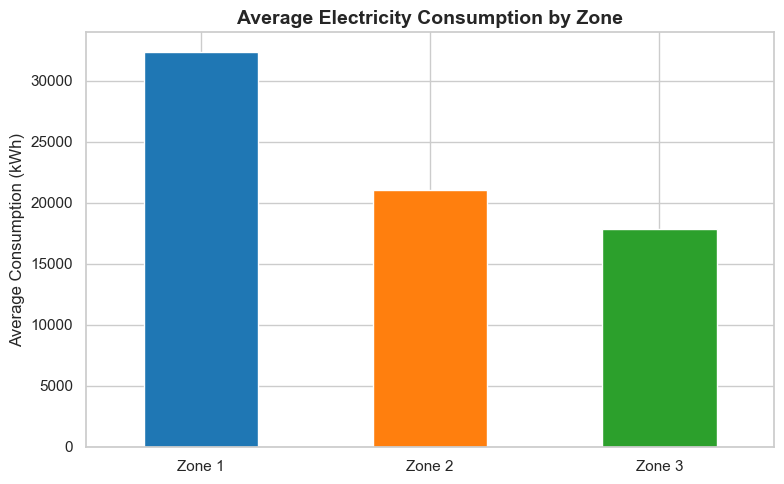

In [19]:
plt.figure(figsize=(8, 5))
mean_consumption.plot(kind='bar', color=['#1f77b4', '#ff7f0e', '#2ca02c'])
plt.title('Average Electricity Consumption by Zone', fontsize=14, fontweight='bold')
plt.ylabel('Average Consumption (kWh)')
plt.xticks(ticks=[0, 1, 2], labels=['Zone 1', 'Zone 2', 'Zone 3'], rotation=0)
plt.tight_layout()
plt.savefig('avg_consumption_by_zone.png')
plt.show()

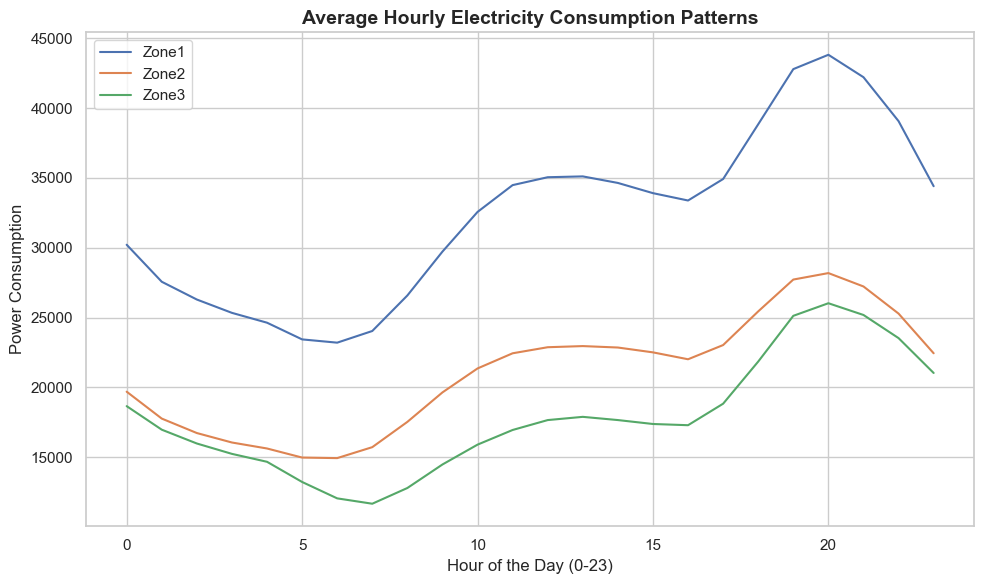

In [20]:
plt.figure(figsize=(10, 6))
for zone in zone_cols:
    plt.plot(hourly_avg.index, hourly_avg[zone], label=zone.replace('PowerConsumption_', ''))
plt.title('Average Hourly Electricity Consumption Patterns', fontsize=14, fontweight='bold')
plt.xlabel('Hour of the Day (0-23)')
plt.ylabel('Power Consumption')
plt.legend()
plt.tight_layout()
plt.savefig('hourly_consumption.png')
plt.show()

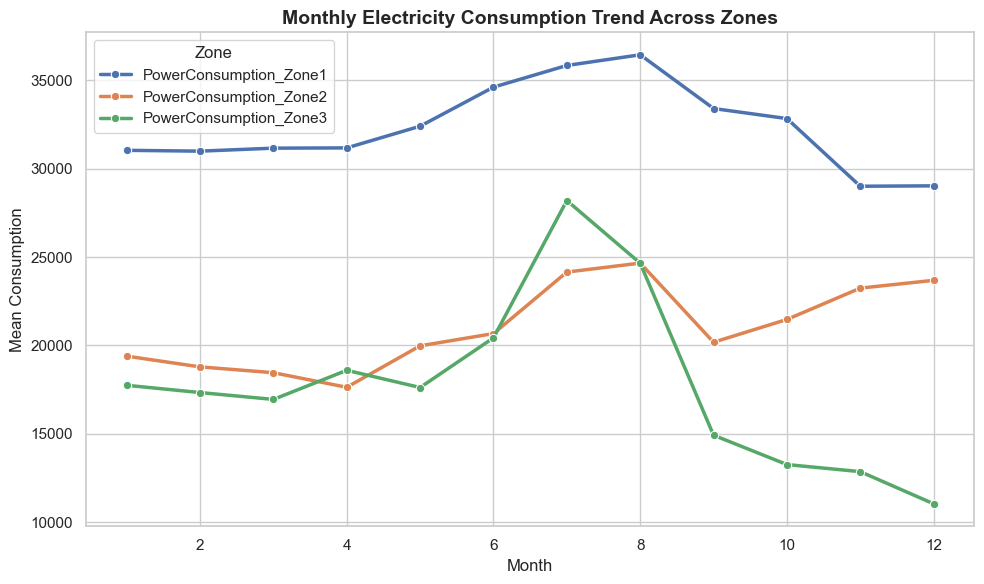

In [21]:
monthly_data = df.groupby('Month')[zone_cols].mean().reset_index()
melted_monthly = monthly_data.melt(id_vars='Month', value_vars=zone_cols, 
                                   var_name='Zone', value_name='Consumption')

plt.figure(figsize=(10, 6))
sns.lineplot(data=melted_monthly, x='Month', y='Consumption', hue='Zone', marker='o', linewidth=2.5)
plt.title('Monthly Electricity Consumption Trend Across Zones', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Mean Consumption')
plt.tight_layout()
plt.savefig('monthly_consumption.png')
plt.show()

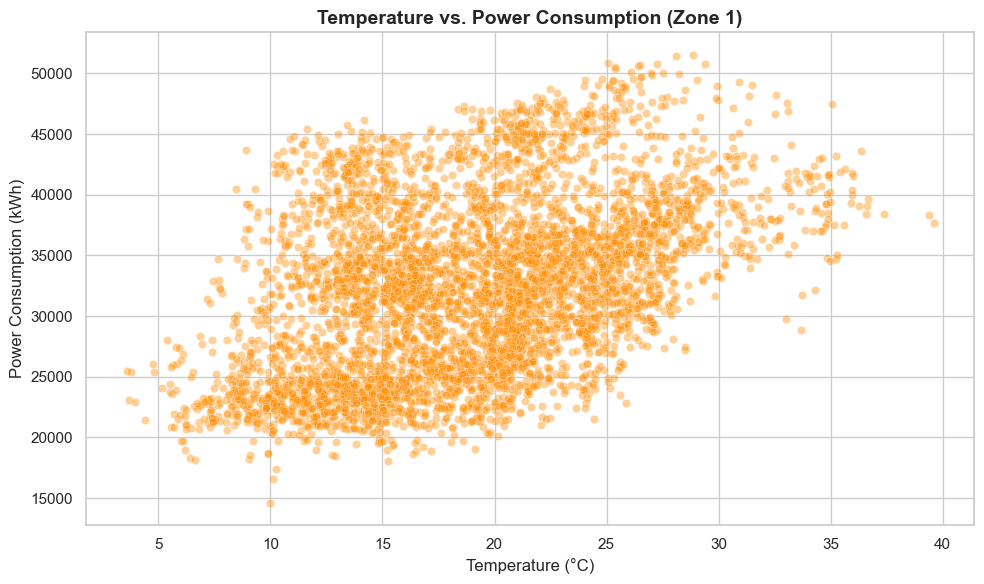

In [22]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df.sample(5000, random_state=42), x='Temperature', y='PowerConsumption_Zone1', 
                alpha=0.4, color='darkorange')
plt.title('Temperature vs. Power Consumption (Zone 1)', fontsize=14, fontweight='bold')
plt.xlabel('Temperature (°C)')
plt.ylabel('Power Consumption (kWh)')
plt.tight_layout()
plt.savefig('temp_vs_zone1.png')
plt.show()

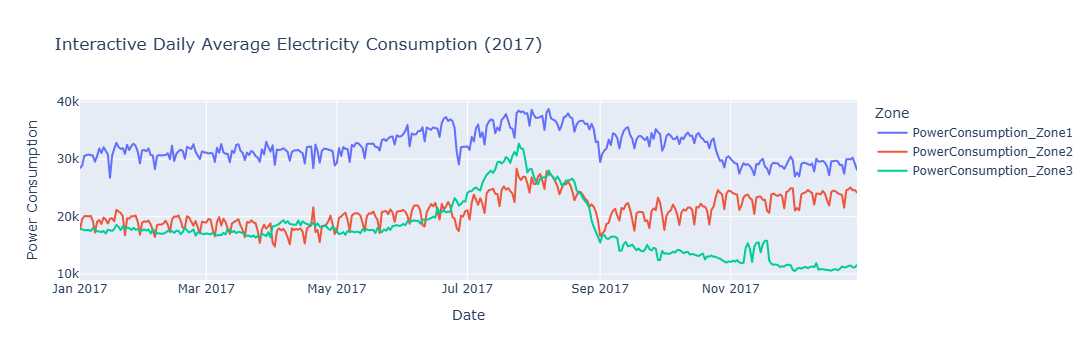

In [23]:
# Resample daily to make interactive plot fast and clear
df_daily = df.set_index('Datetime')[zone_cols].resample('D').mean().reset_index()

fig = px.line(df_daily, x='Datetime', y=['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3'],
              title='Interactive Daily Average Electricity Consumption (2017)',
              labels={'value': 'Power Consumption', 'Datetime': 'Date', 'variable': 'Zone'})
fig.show()

--- PEARSON CORRELATION COEFFICIENTS ---


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,0.440221,0.382428,0.489527
Humidity,-0.287421,-0.294961,-0.233022
WindSpeed,0.167444,0.146413,0.278641
GeneralDiffuseFlows,0.187965,0.157223,0.063376
DiffuseFlows,0.080274,0.044667,-0.038506


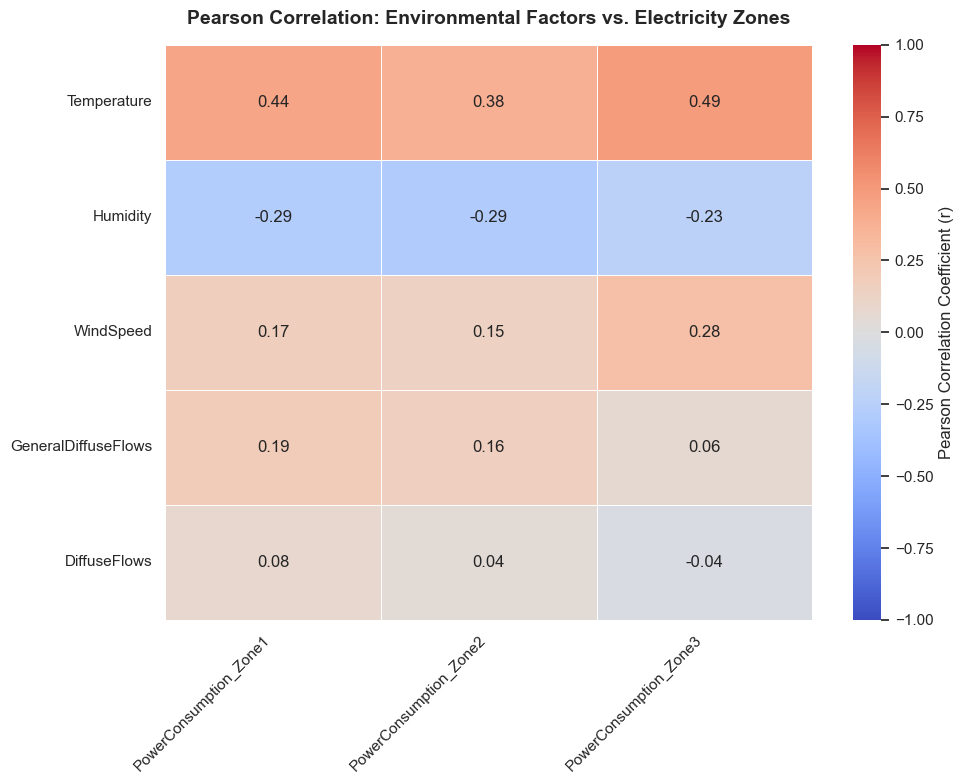

In [24]:
# Define environmental and zone columns
env_cols = ['Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows']
zone_cols = ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

# Calculate the Pearson correlation matrix (default method in pandas .corr() is pearson)
correlation_matrix = df[env_cols + zone_cols].corr(method='pearson')

# Print the specific correlations between zones and environmental factors
print("--- PEARSON CORRELATION COEFFICIENTS ---")
display(correlation_matrix.loc[env_cols, zone_cols])

# Create a professional Heatmap visualization
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix.loc[env_cols, zone_cols], 
            annot=True,         # Show the correlation numbers inside cells
            fmt=".2f",          # Format to 2 decimal places
            cmap='coolwarm',    # Color map (blue = negative, red = positive)
            vmin=-1, vmax=1,    # Set scale from -1 to 1
            linewidths=0.5, 
            cbar_kws={'label': 'Pearson Correlation Coefficient (r)'})

plt.title('Pearson Correlation: Environmental Factors vs. Electricity Zones', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

# Save the plot for your report
plt.savefig('pearson_correlation_heatmap.png', dpi=300)
plt.show()